In [ ]:
%pip install pandas numpy matplotlib scikit-learn imbalanced-learn

### Importação das bibliotecas

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### Carregar o Dataset

In [5]:
# Carregar o dataset
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/winequality-red.csv"
)

df = pd.read_csv(url, sep=";")

# Visualizar as primeiras linhas
print(df.head())

# Verificar dimensões
print("\nDimensões do dataset:", df.shape)

# Verificar valores ausentes
print("\nValores ausentes por coluna:")
print(df.isnull().sum())

# Verificar a distribuição original da qualidade
print("\nDistribuição original das notas:")
print(df["quality"].value_counts().sort_index())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 


Distribuição das classes:
Ruim: 744 amostras (46.53%)
Média: 837 amostras (52.35%)
Boa: 18 amostras (1.13%)


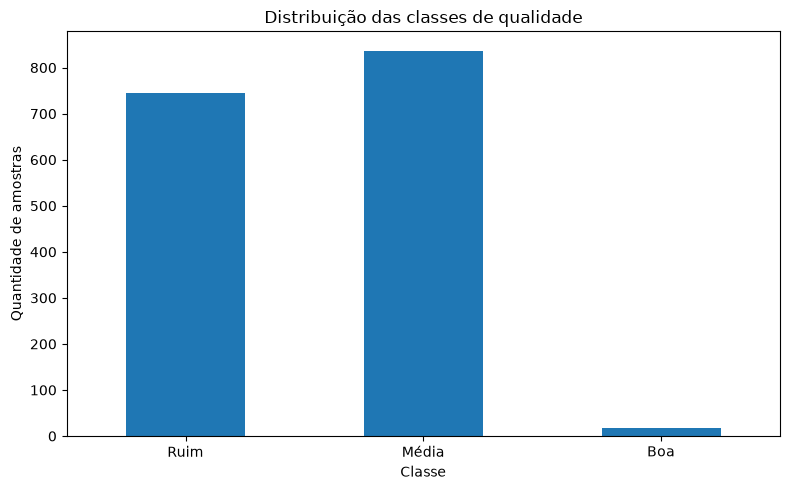

In [6]:
# Criar a variável categórica de qualidade
def classificar_qualidade(nota):
    if nota <= 5:
        return 0
    elif nota <= 7:
        return 1
    else:
        return 2

df["quality_class"] = df["quality"].apply(
    classificar_qualidade
)

# Separar atributos e variável-alvo
X = df.drop(columns=["quality", "quality_class"])
y = df["quality_class"]

# Nomes das classes para os gráficos e relatórios
nomes_classes = ["Ruim", "Média", "Boa"]

# Exibir a distribuição das classes
distribuicao = y.value_counts().sort_index()

print("\nDistribuição das classes:")
for codigo, quantidade in distribuicao.items():
    percentual = quantidade / len(y) * 100
    print(
        f"{nomes_classes[codigo]}: "
        f"{quantidade} amostras ({percentual:.2f}%)"
    )

# Gráfico da distribuição
distribuicao.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.xticks(
    ticks=[0, 1, 2],
    labels=nomes_classes,
    rotation=0
)

plt.title("Distribuição das classes de qualidade")
plt.xlabel("Classe")
plt.ylabel("Quantidade de amostras")
plt.tight_layout()
plt.show()

### Criar a variável categórica de qualidade

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Amostras de treinamento:", len(X_train))
print("Amostras de teste:", len(X_test))

print("\nDistribuição no treinamento:")
print(
    y_train.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nDistribuição no teste:")
print(
    y_test.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Amostras de treinamento: 1279
Amostras de teste: 320

Distribuição no treinamento:
quality_class
0    46.52
1    52.38
2     1.09
Name: proportion, dtype: float64

Distribuição no teste:
quality_class
0    46.56
1    52.19
2     1.25
Name: proportion, dtype: float64


In [8]:
# Configurar a validação cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Valores de k que serão avaliados
valores_k = [1, 3, 5, 7, 11]

# Métricas para avaliar cada configuração
scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy"
}

resultados = []

for k in valores_k:

    # Pipeline: normalização -> SMOTE -> k-NN
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(
            random_state=42,
            k_neighbors=3
        )),
        ("knn", KNeighborsClassifier(
            n_neighbors=k,
            weights="distance"
        ))
    ])

    # Avaliação por validação cruzada
    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    resultados.append({
        "k": k,
        "Acurácia média": scores["test_accuracy"].mean(),
        "Desvio-padrão da acurácia": scores["test_accuracy"].std(),
        "F1-macro médio": scores["test_f1_macro"].mean(),
        "Acurácia balanceada média": scores[
            "test_balanced_accuracy"
        ].mean()
    })

# Organizar os resultados
resultados_df = pd.DataFrame(resultados)

print(resultados_df.round(4).to_string(index=False))

 k  Acurácia média  Desvio-padrão da acurácia  F1-macro médio  Acurácia balanceada média
 1          0.7060                     0.0100          0.4975                     0.5193
 3          0.7139                     0.0119          0.5117                     0.5471
 5          0.7240                     0.0173          0.5170                     0.5536
 7          0.7060                     0.0026          0.5064                     0.5419
11          0.6990                     0.0141          0.5077                     0.5594


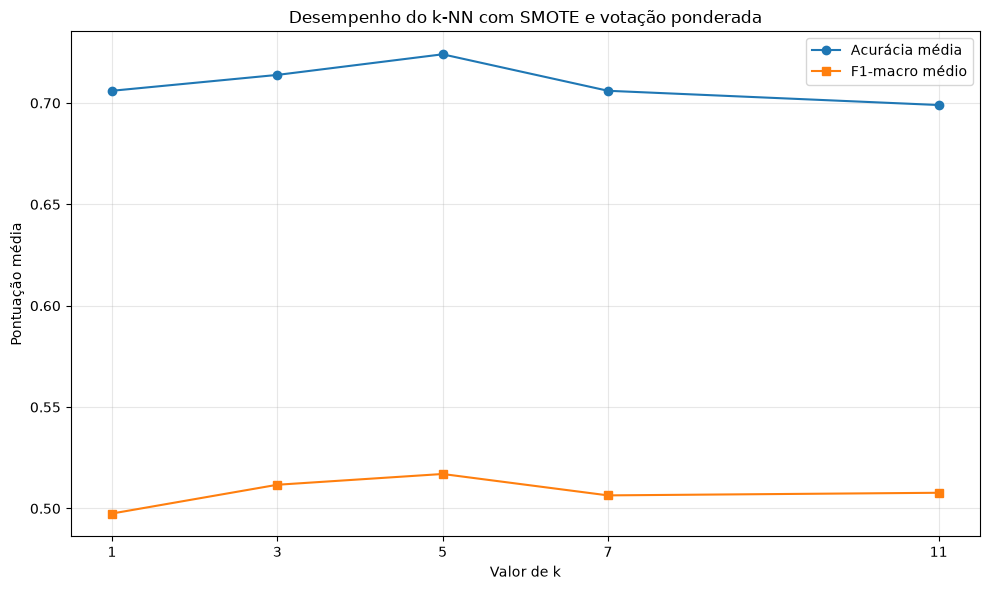

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    resultados_df["k"],
    resultados_df["Acurácia média"],
    marker="o",
    label="Acurácia média"
)

plt.plot(
    resultados_df["k"],
    resultados_df["F1-macro médio"],
    marker="s",
    label="F1-macro médio"
)

plt.xlabel("Valor de k")
plt.ylabel("Pontuação média")
plt.title("Desempenho do k-NN com SMOTE e votação ponderada")
plt.xticks(valores_k)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
melhor_linha = resultados_df.loc[
    resultados_df["F1-macro médio"].idxmax()
]

melhor_k = int(melhor_linha["k"])

print("Melhor k segundo o F1-macro:", melhor_k)
print(
    "F1-macro médio:",
    round(melhor_linha["F1-macro médio"], 4)
)
print(
    "Acurácia média:",
    round(melhor_linha["Acurácia média"], 4)
)
print(
    "Acurácia balanceada média:",
    round(melhor_linha["Acurácia balanceada média"], 4)
)

Melhor k segundo o F1-macro: 5
F1-macro médio: 0.517
Acurácia média: 0.724
Acurácia balanceada média: 0.5536


In [11]:
# Criar o modelo final com o melhor k
modelo_final = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        random_state=42,
        k_neighbors=3
    )),
    ("knn", KNeighborsClassifier(
        n_neighbors=melhor_k,
        weights="distance"
    ))
])

# Treinar somente com os dados de treinamento
modelo_final.fit(X_train, y_train)

# Fazer previsões no conjunto de teste
y_pred = modelo_final.predict(X_test)

print("Modelo final treinado.")
print("Melhor valor de k:", melhor_k)

Modelo final treinado.
Melhor valor de k: 5


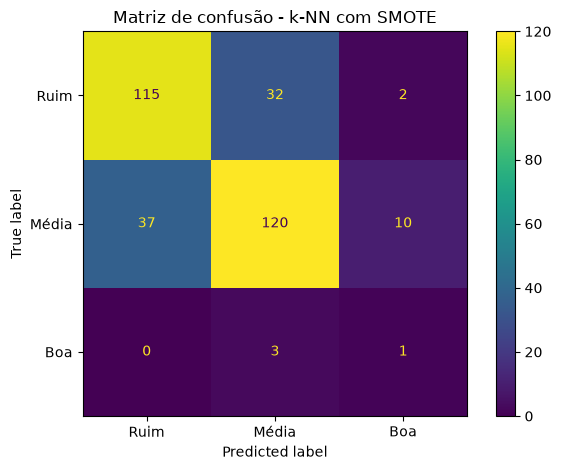


Matriz de confusão:
[[115  32   2]
 [ 37 120  10]
 [  0   3   1]]


In [12]:
matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=nomes_classes
)

disp.plot(values_format="d")

plt.title("Matriz de confusão - k-NN com SMOTE")
plt.tight_layout()
plt.show()

print("\nMatriz de confusão:")
print(matriz)

In [13]:
print("Acurácia geral:")
print(round(accuracy_score(y_test, y_pred), 4))

print("\nAcurácia balanceada:")
print(round(balanced_accuracy_score(y_test, y_pred), 4))

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=nomes_classes,
        digits=4,
        zero_division=0
    )
)

Acurácia geral:
0.7375

Acurácia balanceada:
0.5801

Relatório de classificação:
              precision    recall  f1-score   support

        Ruim     0.7566    0.7718    0.7641       149
       Média     0.7742    0.7186    0.7453       167
         Boa     0.0769    0.2500    0.1176         4

    accuracy                         0.7375       320
   macro avg     0.5359    0.5801    0.5424       320
weighted avg     0.7573    0.7375    0.7462       320



In [14]:
# Copiar a matriz de confusão
erros = matriz.copy()

# Zerar a diagonal principal, que contém os acertos
np.fill_diagonal(erros, 0)

# Identificar o maior número de erros fora da diagonal
i, j = np.unravel_index(
    np.argmax(erros),
    erros.shape
)

quantidade_erros = erros[i, j]

if quantidade_erros > 0:
    print(
        f"Maior confusão: classe real '{nomes_classes[i]}' "
        f"classificada como '{nomes_classes[j]}'."
    )
    print("Quantidade de erros:", quantidade_erros)
else:
    print("Nenhum erro de classificação foi encontrado.")

Maior confusão: classe real 'Média' classificada como 'Ruim'.
Quantidade de erros: 37


In [15]:
pares_erros = {
    "Ruim ↔ Média": matriz[0, 1] + matriz[1, 0],
    "Ruim ↔ Boa": matriz[0, 2] + matriz[2, 0],
    "Média ↔ Boa": matriz[1, 2] + matriz[2, 1]
}

print("Erros agrupados por par de classes:")

for par, quantidade in pares_erros.items():
    print(f"{par}: {quantidade} erros")

maior_par = max(pares_erros, key=pares_erros.get)

print("\nPar com maior confusão:", maior_par)

Erros agrupados por par de classes:
Ruim ↔ Média: 69 erros
Ruim ↔ Boa: 2 erros
Média ↔ Boa: 13 erros

Par com maior confusão: Ruim ↔ Média


In [16]:
# Modelo de referência: sem SMOTE e sem votação ponderada
modelo_referencia = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=melhor_k,
        weights="uniform"
    ))
])

# Modelo proposto: com SMOTE e votação ponderada
modelo_proposto = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        random_state=42,
        k_neighbors=3
    )),
    ("knn", KNeighborsClassifier(
        n_neighbors=melhor_k,
        weights="distance"
    ))
])

# Avaliar os dois modelos usando exatamente os mesmos folds
metricas_comparacao = {
    "Acurácia": "accuracy",
    "F1-macro": "f1_macro",
    "Acurácia balanceada": "balanced_accuracy"
}

resultados_comparacao = []

for nome, modelo in [
    ("Referência", modelo_referencia),
    ("SMOTE + distância", modelo_proposto)
]:

    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas_comparacao,
        n_jobs=-1
    )

    resultados_comparacao.append({
        "Modelo": nome,
        "Acurácia": scores["test_Acurácia"].mean(),
        "F1-macro": scores["test_F1-macro"].mean(),
        "Acurácia balanceada": scores[
            "test_Acurácia balanceada"
        ].mean()
    })

comparacao_df = pd.DataFrame(resultados_comparacao)

print(comparacao_df.round(4).to_string(index=False))

           Modelo  Acurácia  F1-macro  Acurácia balanceada
       Referência    0.7131    0.4763               0.4786
SMOTE + distância    0.7240    0.5170               0.5536
